In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix


df = pd.read_csv('diabetes.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [3]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols] = df[cols].replace(0, np.nan)
(df==0).sum()

Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [4]:
df['InsulinResistance'] = df['Glucose'] * df['Insulin']/405
df['AgeRisk'] = df['BMI'] * df['Age']

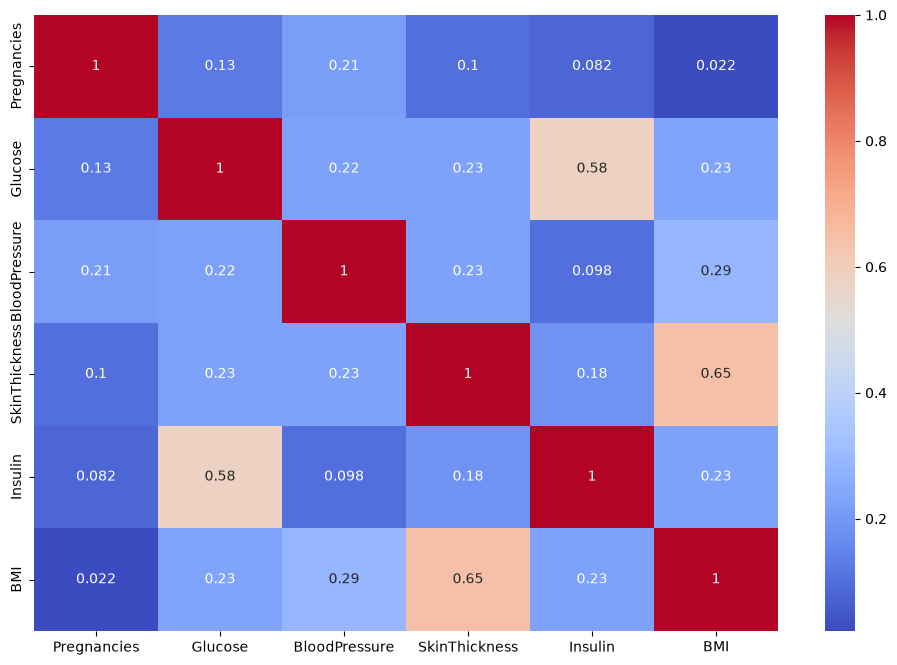

In [ ]:
corr = df[['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']].corr()
plt.figure(figsize=(12, 8))
heat = sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

<Axes: xlabel='Outcome'>

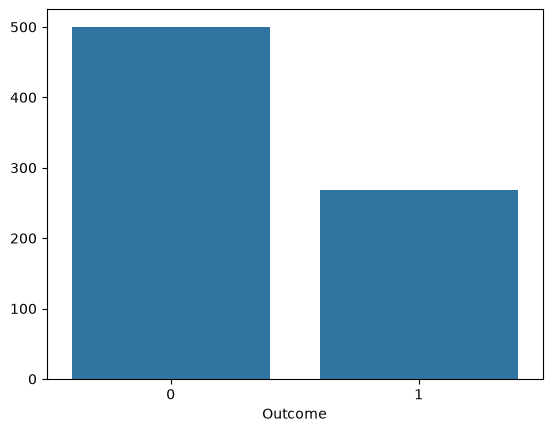

In [6]:
outcomeValues = df['Outcome'].value_counts()
sns.barplot(x=outcomeValues.index, y=outcomeValues.values)

In [7]:
X = df.drop(['Outcome'], axis=1)
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

medie = X_train.mean()
X_train = X_train.fillna(medie)
X_test = X_test.fillna(medie)

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
gnb_base = GaussianNB()
gnb_base.fit(X_train_scaled, y_train)
print(classification_report(y_test, gnb_base.predict(X_test_scaled)))

              precision    recall  f1-score   support

           0       0.78      0.74      0.76       100
           1       0.56      0.61      0.58        54

    accuracy                           0.69       154
   macro avg       0.67      0.68      0.67       154
weighted avg       0.70      0.69      0.70       154



In [10]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train, sample_weight=sample_weights)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[307.,307.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 10)","[[-0.15,-0.37,-0.13,...,-0.18,-0.21,-0.27], [ 0.28, 0.7 , 0.25,..., 0.33, 0.39, 0.51]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 10)","[[0.81,0.61,0.98,...,0.96,0.67,0.84], [1.23,0.97,0.94,...,0.91,1.38,0.91]]"


In [11]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome',
       'InsulinResistance', 'AgeRisk'],
      dtype='str')

In [12]:
y_pred = gnb.predict(X_test_scaled)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.71      0.75       100
           1       0.55      0.65      0.59        54

    accuracy                           0.69       154
   macro avg       0.67      0.68      0.67       154
weighted avg       0.70      0.69      0.69       154

[[71 29]
 [19 35]]


In [13]:
pregnancies = float(input('Insert patient pregnancies:'))
glucose = float(input('Insert patient glucose level:'))
bloodpressure = float(input('Insert patient blood pressure:'))
skinthickness = float(input('Insert patient skin thickness:'))
insulin = float(input('Insert patient insulin level:'))
bmi = float(input('Insert patient bmi:'))
diabetespedigree = float(input('Insert patient diabetes pedigree function: '))
age = float(input('Insert patient age:'))


X_input = pd.DataFrame([{
    'Pregnancies': pregnancies,
    'Glucose': glucose,
    'BloodPressure': bloodpressure,
    'SkinThickness': skinthickness,
    'Insulin': insulin,
    'BMI': bmi,
    'DiabetesPedigreeFunction': diabetespedigree,
    'Age': age
}])

X_input['InsulinResistance'] = X_input['Glucose'] * X_input['Insulin']/405
X_input['AgeRisk'] = X_input['BMI'] * X_input['Age']


X_input_scaled = scaler.transform(X_input)

y_input_pred = gnb.predict(X_input_scaled)
print(y_input_pred)

ValueError: could not convert string to float: ''